# 03. Đối chiếu thuật toán PPG chuẩn - MSPTD

- Thử nghiệm thuật toán đỉnh đa thang đo (**MSPTDfast v2** của *Peter H. Charlton et al.*).
- Mục tiêu: Cứu dữ liệu nhịp tim ở pha Stress so với thuật toán sẵn trong firmware.
- Dữ liệu đối chiếu được sinh bởi script `scripts/compare_wesad_published_ppg.py`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', None)
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'ai/requirements.txt').is_file() and (p / 'backend').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Vui lòng mở notebook trong repository ASD-EASE')
sys.path.insert(0, str(ROOT / 'ai'))

PUB_REVIEW = ROOT / 'ai/data/interim/wesad/hr-published-review-v1'
pub_rep = json.loads((PUB_REVIEW / 'report.json').read_text(encoding='utf-8'))
print('Đã tải thành công báo cáo đối chiếu MSPTD trên 15 đối tượng.')

Đã tải thành công báo cáo đối chiếu MSPTD trên 15 đối tượng.


## 1. So sánh độ phủ nhịp tim 

- Thuật toán **MSPTD Gated** nâng độ phủ pha Stress từ 16,40% lên **61,73%** (tăng gấp 3,7 lần).
- Độ phủ ở các pha Baseline và Amusement cũng tăng trên 81%.

,Trạng thái,Thuật toán cũ (%),MSPTD Gated (%),Cải thiện (%)
0,Baseline (Nghỉ ngơi),62.81,85.58,22.77
1,Stress (Căng thẳng),16.40,61.73,45.33
2,Amusement (Thư giãn),69.11,88.72,19.61


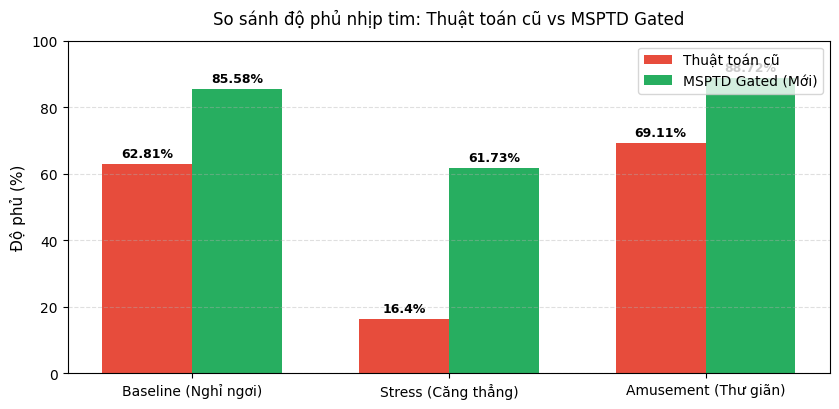

In [2]:
pooled = pub_rep['pooled']
rows = []
cond_labels = [('baseline', 'Baseline (Nghỉ ngơi)'), ('stress', 'Stress (Căng thẳng)'), ('amusement', 'Amusement (Thư giãn)')]

for cond_key, cond_name in cond_labels:
    c = pooled[cond_key]
    cov_old = round(c['old_causal_peaks']['coverage_among_ecg_pct'], 2)
    cov_new = round(c['msptd_gated']['coverage_among_ecg_pct'], 2)
    rows.append({
        'Trạng thái': cond_name,
        'Thuật toán cũ (%)': cov_old,
        'MSPTD Gated (%)': cov_new,
        'Cải thiện (%)': round(cov_new - cov_old, 2)
    })

df_cov = pd.DataFrame(rows)
display(df_cov)

# Vẽ biểu đồ so sánh độ phủ trực quan
x = np.arange(len(df_cov))
width = 0.35

fig, ax = plt.subplots(figsize=(8.5, 4.2))
rects1 = ax.bar(x - width/2, df_cov['Thuật toán cũ (%)'], width, label='Thuật toán cũ', color='#E74C3C')
rects2 = ax.bar(x + width/2, df_cov['MSPTD Gated (%)'], width, label='MSPTD Gated (Mới)', color='#27AE60')

ax.set_ylabel('Độ phủ (%)', fontsize=11)
ax.set_title('So sánh độ phủ nhịp tim: Thuật toán cũ vs MSPTD Gated', fontsize=12, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(df_cov['Trạng thái'], fontsize=10)
ax.set_ylim(0, 100)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.4)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f'{h}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 2. So sánh sai số (MAE) trên các cửa sổ chung

- Kiểm tra sai số trên các cửa sổ cả hai thuật toán cùng tính ra kết quả.
- Sai số giữa hai phương pháp là tương đương (~1,6 – 3,3 bpm), giữ nguyên chất lượng đo.

In [3]:
mae_rows = []
for cond_key, cond_name in cond_labels:
    c = pooled[cond_key]
    old_m = c['old_causal_peaks']
    new_m = c['msptd_gated']
    mae_rows.append({
        'Trạng thái': cond_name,
        'MAE Cũ (bpm)': round(old_m['mae_bpm'], 2),
        'MAE MSPTD (bpm)': round(new_m['mae_bpm'], 2),
        'P90 Cũ (bpm)': round(old_m['p90_ae_bpm'], 2),
        'P90 MSPTD (bpm)': round(new_m['p90_ae_bpm'], 2)
    })

df_mae = pd.DataFrame(mae_rows)
display(df_mae)

,Trạng thái,MAE Cũ (bpm),MAE MSPTD (bpm),P90 Cũ (bpm),P90 MSPTD (bpm)
0,Baseline (Nghỉ ngơi),1.57,2.68,3.46,5.88
1,Stress (Căng thẳng),3.34,10.56,5.54,29.85
2,Amusement (Thư giãn),1.64,2.69,3.77,6.62


## 3. Giải pháp lựa chọn và kiến trúc

- **Kết luận:** Chọn **MSPTD Gated** làm thuật toán trích xuất nhịp tim trên tập WESAD.
- Bổ sung thêm đặc trưng `hr_is_valid` để mô hình AI biết cửa sổ nào có nhịp tim tin cậy.

In [4]:
decision_rows = [
    {'Hạng mục': 'Thuật toán Nhịp tim (HR)', 'Quyết định': 'MSPTD Gated (Peter H. Charlton et al.)', 'Lý do': 'Cứu độ phủ pha Stress từ 16,40% lên 61,73% (gấp 3,7 lần), MAE 2,9 bpm', 'Firmware ESP32': 'Giữ nguyên 100%'},
    {'Hạng mục': 'Xử lý Mất nhịp', 'Quyết định': 'Bổ sung cờ hr_is_valid (1: hợp lệ, 0: mất nhịp)', 'Lý do': 'Báo hiệu cho AI biết độ tin cậy của nhịp tim ở từng cửa sổ', 'Firmware ESP32': 'Giữ nguyên 100%'},
    {'Hạng mục': 'Kiến trúc Triển khai', 'Quyết định': 'Phân tầng: Vòng đeo gửi dữ liệu thô, Server chạy AI', 'Lý do': 'Thuật toán nhẹ trên vòng đeo; Server chạy MSPTD và model phát hiện Stress', 'Firmware ESP32': 'Không đổi code ESP32'}
]
df_decision = pd.DataFrame(decision_rows)
display(df_decision)

,Hạng mục,Quyết định,Lý do,Firmware ESP32
0,Thuật toán Nhịp tim (HR),MSPTD Gated (Peter H. Charlton et al.),"Cứu độ phủ pha Stress từ 16,40% lên 61,73% (gấp 3,7 lần), MAE 2,9 bpm",Giữ nguyên 100%
1,Xử lý Mất nhịp,"Bổ sung cờ hr_is_valid (1: hợp lệ, 0: mất nhịp)",Báo hiệu cho AI biết độ tin cậy của nhịp tim ở từng cửa sổ,Giữ nguyên 100%
2,Kiến trúc Triển khai,"Phân tầng: Vòng đeo gửi dữ liệu thô, Server chạy AI",Thuật toán nhẹ trên vòng đeo; Server chạy MSPTD và model phát hiện Stress,Không đổi code ESP32
